### Notebook Overview
This notebook demonstrates a complete workflow for predicting customer churn using a Deep Learning approach (Artificial Neural Network):

* **Data Loading & Exploration:** Initial loading of the dataset containing 10,000 customers, looking at descriptive statistics, and checking for duplicates.
* **Feature Engineering:** Removing irrelevant features (`RowNumber`, `CustomerId`, `Surname`) and encoding categorical features (`Geography`, `Gender`) using one-hot encoding.
* **Data Preprocessing:** Splitting the dataset into Training and Testing sets, and scaling features using `StandardScaler` for neural network compatibility.
* **Model Development:** Designing a Sequential Neural Network using TensorFlow/Keras with two Dense hidden layers (ReLU activation) and an output layer (Sigmoid activation for binary classification).
* **Model Training & Evaluation:** Training the model over 100 epochs, visualizing loss and accuracy trajectories to monitor overfitting, and evaluating performance on unseen test data.

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sarahashmi/churn-modeling-csv/Churn_Modelling.csv


In [ ]:
df = pd.read_csv('/kaggle/input/datasets/sarahashmi/churn-modeling-csv/Churn_Modelling.csv')

In [ ]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
df.shape

(10000, 14)

In [ ]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [ ]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [ ]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [ ]:
df.drop(columns = ['RowNumber',	'CustomerId',	'Surname'],inplace = True)

In [ ]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
df = pd.get_dummies(
    df,
    columns=['Geography', 'Gender'],
    drop_first=True,
    dtype=int
)

KeyError: "None of [Index(['Geography', 'Gender'], dtype='object')] are in the [columns]"

In [ ]:
df

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,0,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,1,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,1,True,False,True


In [ ]:
X = df.drop(columns = ['Exited'])
y = df['Exited']

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 1)

In [ ]:
X

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,True,False,True


In [ ]:
y

0       1
1       0
2       1
3       0
4       0
       ..
9995    0
9996    0
9997    1
9998    1
9999    0
Name: Exited, Length: 10000, dtype: int64

In [ ]:
X_train.shape

(8000, 11)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)



In [ ]:
X_train_scaled

array([[-0.23082038, -0.94449979, -0.70174202, ...,  1.71490137,
        -0.57273139,  0.91509065],
       [-0.25150912, -0.94449979, -0.35520275, ..., -0.58312392,
        -0.57273139, -1.09278791],
       [-0.3963303 ,  0.77498705,  0.33787579, ...,  1.71490137,
        -0.57273139, -1.09278791],
       ...,
       [ 0.22433188,  0.58393295,  1.3774936 , ..., -0.58312392,
        -0.57273139, -1.09278791],
       [ 0.13123255,  0.01077067,  1.03095433, ..., -0.58312392,
        -0.57273139, -1.09278791],
       [ 1.1656695 ,  0.29735181,  0.33787579, ...,  1.71490137,
        -0.57273139,  0.91509065]])

In [ ]:
X_test_scaled

array([[-1.05008411,  0.75175306, -1.01618321, ..., -0.56118125,
        -0.57812007,  0.90179633],
       [ 0.29631699, -0.47907689, -0.67334137, ..., -0.56118125,
        -0.57812007,  0.90179633],
       [-1.24686581,  0.27835693, -1.01618321, ..., -0.56118125,
        -0.57812007, -1.10889783],
       ...,
       [-0.87401628, -0.47907689,  1.72655149, ..., -0.56118125,
         1.72974448,  0.90179633],
       [-0.31474197, -0.85779379, -1.01618321, ...,  1.78195548,
        -0.57812007, -1.10889783],
       [ 0.0373937 ,  1.22514919,  1.38370966, ...,  1.78195548,
        -0.57812007,  0.90179633]])

In [ ]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

I0000 00:00:1793700844.365771      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793700865.406176      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [ ]:
model = Sequential()

model.add(Dense(11,activation = 'relu',input_dim = 11))
model.add(Dense(11,activation = 'relu'))
model.add(Dense(1,activation = 'sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276 (1.08 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(loss = 'binary_crossentropy',optimizer = 'Adam',metrics = ['Accuracy'])

In [ ]:
history = model.fit(X_train_scaled,y_train,epochs = 100,validation_split = 0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - Accuracy: 0.8655 - loss: 0.3227 - val_Accuracy: 0.8512 - val_loss: 0.3457
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - Accuracy: 0.8652 - loss: 0.3230 - val_Accuracy: 0.8512 - val_loss: 0.3475
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - Accuracy: 0.8666 - loss: 0.3231 - val_Accuracy: 0.8512 - val_loss: 0.3454
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - Accuracy: 0.8655 - loss: 0.3227 - val_Accuracy: 0.8506 - val_loss: 0.3443
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - Accuracy: 0.8655 - loss: 0.3224 - val_Accuracy: 0.8494 - val_loss: 0.3481
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - Accuracy: 0.8655 - loss: 0.3220 - val_Accuracy: 0.8506 - val_loss: 0.3455
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - Accuracy: 0.8631 - loss: 0.3224 - val_Accuracy: 0.8500 - val_loss: 0.3456
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - Accuracy: 0.8664 - loss: 0.3224 - val_Accu

In [ ]:
model.layers[0].get_weights()  # gives weights and bias for first layer


[array([[ 0.16129321, -0.48077744,  0.2266788 ,  0.35381874,  0.1647544 ,
         -0.34977657, -0.02669463,  0.22714907,  0.29058814, -0.02595775,
         -0.02925769],
        [-0.7059571 , -0.5992346 ,  0.09426684,  0.08599629, -0.29462212,
         -0.8018337 ,  0.2843786 ,  0.04121245,  0.7931627 , -0.2539897 ,
         -0.4393692 ],
        [-0.10824729,  0.45732933, -0.03324009,  0.32313725, -0.15165381,
         -0.27535632,  0.21563047,  0.09376483,  0.21128038, -0.16398211,
         -0.12816556],
        [-0.09454098, -0.05476332,  0.13446346, -0.43684322, -0.12206224,
         -0.6627948 ,  0.0519581 ,  0.04779863, -0.14546429, -0.75166935,
         -0.5884478 ],
        [-0.02621766, -0.30730438,  1.1419092 , -0.5824196 , -0.0973465 ,
         -0.09612626, -0.36119065, -1.1584342 , -0.09462833, -1.0548836 ,
         -0.10240161],
        [ 0.01345048, -0.11466629,  0.12855485,  0.4397999 ,  0.19578944,
         -0.3309927 ,  0.00761037,  0.08171225,  0.2937617 , -0.0898840

In [ ]:
model.layers[1].get_weights()

[array([[-1.0041993 ,  0.436714  ,  0.20500305, -1.0750113 ,  0.5522693 ,
         -0.19959772, -0.5328219 , -0.08472868,  0.27601966, -0.8653094 ,
          0.6497793 ],
        [ 0.03037844, -0.16657048, -0.5181111 , -0.627569  ,  0.56487346,
          0.32046297,  0.08961338,  0.01947782,  0.36630446, -0.04704082,
         -0.08075348],
        [ 0.73557746,  0.34944448, -0.711711  ,  1.0394146 , -0.12997313,
          0.0991399 ,  0.7827588 , -0.21033157, -0.34323597, -0.69235706,
          0.01929833],
        [ 0.4265484 , -0.50037897, -0.06276208, -0.05677376, -0.01773657,
          0.7604949 , -0.1775146 ,  0.27786085,  0.03168414,  0.23728743,
          0.1538751 ],
        [-0.252201  ,  0.4572696 ,  0.65463245,  0.17160009, -0.1065864 ,
         -0.0774663 , -0.34649715,  0.51274437,  0.2187526 ,  0.01901336,
          0.28101858],
        [-0.13420263, -0.98949367, -0.086395  ,  0.33679315, -0.2740037 ,
          0.26046494,  0.29671833,  0.087745  ,  0.3940594 , -0.5103980

In [ ]:
model.layers[2].get_weights()

[array([[ 0.99432445],
        [-0.54680157],
        [ 0.36677286],
        [ 1.2273221 ],
        [ 0.7279946 ],
        [-0.9829201 ],
        [ 0.65983653],
        [-0.37538254],
        [-0.7525357 ],
        [ 0.91274536],
        [-0.55767184]], dtype=float32),
 array([-0.07424805], dtype=float32)]

In [ ]:
y_log = model.predict(X_test_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [ ]:
y_pred = np.where(y_log>0.5,1,0)   # creates a thresshold of 0.5 to convert probability into 0 and 1

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.858

In [ ]:
import matplotlib.pyplot as plt


In [ ]:
history.history

{'Accuracy': [0.8654687404632568,
  0.8651562333106995,
  0.8665624856948853,
  0.8654687404632568,
  0.8654687404632568,
  0.8654687404632568,
  0.8631250262260437,
  0.866406261920929,
  0.8656250238418579,
  0.8642187714576721,
  0.864062488079071,
  0.8662499785423279,
  0.8650000095367432,
  0.8656250238418579,
  0.8657812476158142,
  0.8650000095367432,
  0.8657812476158142,
  0.8642187714576721,
  0.8678125143051147,
  0.8653125166893005,
  0.8662499785423279,
  0.8639062643051147,
  0.8675000071525574,
  0.8676562309265137,
  0.8654687404632568,
  0.8643749952316284,
  0.8656250238418579,
  0.8670312762260437,
  0.8659374713897705,
  0.8681250214576721,
  0.8665624856948853,
  0.8662499785423279,
  0.8670312762260437,
  0.8670312762260437,
  0.8657812476158142,
  0.8696874976158142,
  0.8660937547683716,
  0.8657812476158142,
  0.8657812476158142,
  0.8675000071525574,
  0.8685937523841858,
  0.8659374713897705,
  0.8678125143051147,
  0.8654687404632568,
  0.8662499785423279,


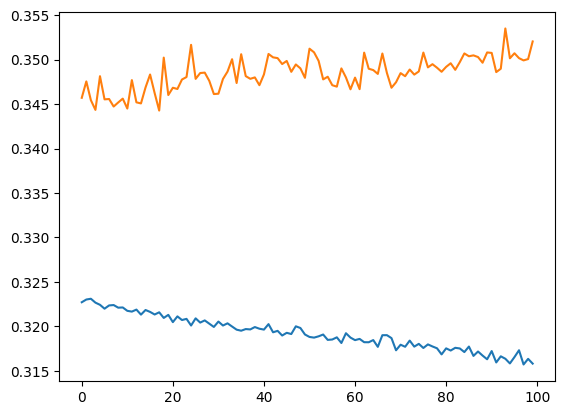

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

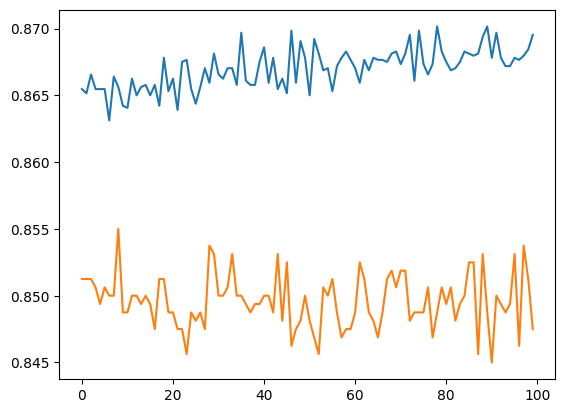

In [ ]:
plt.plot(history.history['Accuracy'])
plt.plot(history.history['val_Accuracy'])